# クラスタリング (フラグで分けたあとの顧客)

## 目的

[ADR 010](../docs/decisions/010_rule_flags_and_clustering_scope.md) に従い、リピーターと遅延経験者をフラグで分けたあと、残りの顧客を連続値中心の特徴量でクラスタリングする。

| 試行 | 入力する特徴量 | 判断したいこと |
|---|---|---|
| 1 | `total_items_amount` (log1p)、`days_since_last_purchase` | 金額と最近性だけで、意味のある顧客群が得られるか |
| 2 | 試行 1 ＋ `avg_review_score` | 満足度を加えると、顧客群がどう変わるか |

シルエット係数を最大にすることではなく、**購買行動として解釈できる顧客群を見つけること**を優先する。

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.cloud import bigquery
from matplotlib.colors import LinearSegmentedColormap
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

client = bigquery.Client()  # プロジェクトは gcloud の設定から取得する
features = client.query("select * from olist_mart.customer_features").to_dataframe()

# NUMERIC は Decimal、真偽値は boolean として読まれるため float にする
NUMERIC_COLUMNS = [
    "total_items_amount",
    "order_count",
    "item_count",
    "days_since_last_purchase",
    "credit_card_order_ratio",
    "avg_review_score",
    "has_review_comment",
    "late_delivery_ratio",
]
raw = features[NUMERIC_COLUMNS].astype("float")
raw.shape

/home/seven/workspace/olist-data-platform/.venv/lib/python3.12/site-packages/google/cloud/bigquery/table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


(93358, 8)

## 1. フラグと、クラスタリングの対象

- `is_repeat_customer`: `order_count >= 2`
- `has_late_delivery`: `late_delivery_ratio > 0` (`late_delivery_ratio` が NULL なら NULL)

2 つのフラグは独立して持つ。どちらにも当てはまらない顧客をクラスタリングの対象にし、入力する特徴量に NULL がある顧客は学習から外す (ADR 009)。

In [2]:
is_repeat_customer = raw["order_count"] >= 2
has_late_delivery = (raw["late_delivery_ratio"] > 0).astype("boolean").mask(raw["late_delivery_ratio"].isna())

flagged = is_repeat_customer | has_late_delivery.fillna(False)
late_unknown = has_late_delivery.isna() & ~is_repeat_customer
target = ~flagged & ~late_unknown

INPUT_FEATURES = ["total_items_amount", "days_since_last_purchase", "avg_review_score"]  # 試行 1・2 で使う列の和集合
is_train = target & raw[INPUT_FEATURES].notna().all(axis=1)

pd.Series({
    "全顧客": len(raw),
    "リピーター": is_repeat_customer.sum(),
    "遅延経験者": has_late_delivery.sum(),
    "両方に当てはまる": (is_repeat_customer & has_late_delivery.fillna(False)).sum(),
    "リピーターまたは遅延経験者": flagged.sum(),
    "遅れの有無が不明 (リピーターを除く)": late_unknown.sum(),
    "クラスタリングの対象": target.sum(),
    "対象のうち、入力に NULL がある": (target & ~is_train).sum(),
    "学習に使う顧客": is_train.sum(),
}).to_frame("customers")

,customers
全顧客,93358
リピーター,2801
遅延経験者,6498
両方に当てはまる,303
リピーターまたは遅延経験者,8996
遅れの有無が不明 (リピーターを除く),8
クラスタリングの対象,84354
対象のうち、入力に NULL がある,453
学習に使う顧客,83901


In [3]:
# ADR 010 の人数と一致することを確かめる
assert flagged.sum() == 8_996
assert target.sum() == 84_354
assert is_train.sum() == 83_901

train_raw = raw[is_train]

## 2. 入力する特徴量の分布

クラスタリングの前に、金額と最近性の 2 次元の分布を見る。はっきりした塊 (山) がいくつかあれば、K-means はそれを見つけられる。
塊がなく、なだらかに広がっている場合は、K-means は連続した分布を区切るだけになる。

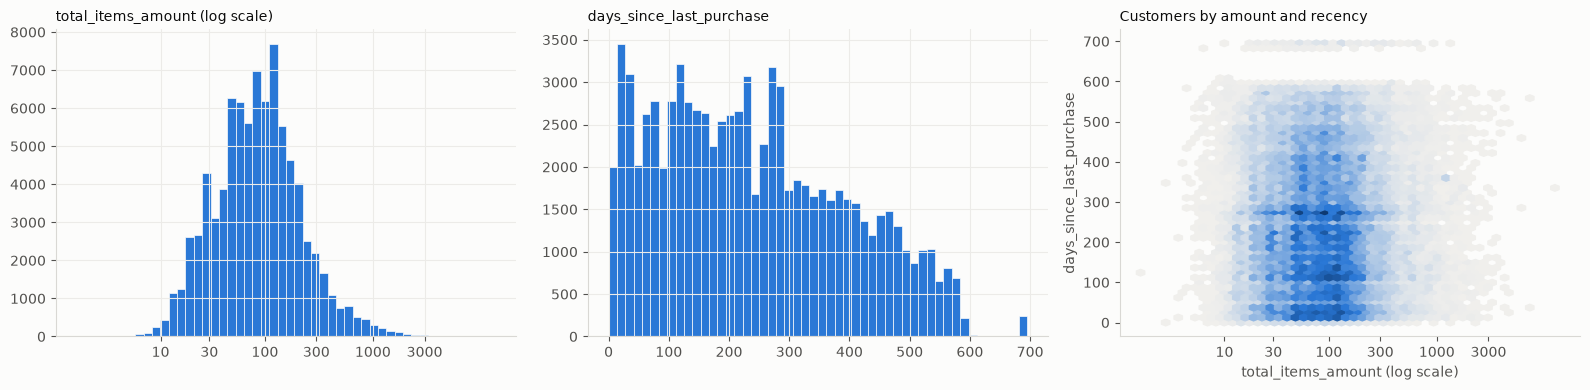

In [4]:
# グラフ内の文字は英語にする (日本語フォントがない環境でも同じように表示するため)
SURFACE = "#fcfcfb"
TEXT_PRIMARY = "#0b0b0b"
TEXT_SECONDARY = "#52514e"
SERIES = "#2a78d6"  # 単一系列のため 1 色のみ

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": "#d9d8d4",
    "axes.labelcolor": TEXT_SECONDARY,
    "axes.titlecolor": TEXT_PRIMARY,
    "xtick.color": TEXT_SECONDARY,
    "ytick.color": TEXT_SECONDARY,
    "axes.grid": True,
    "grid.color": "#ecebe8",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# 人数の多さは 1 色の濃淡で表す
sequential = LinearSegmentedColormap.from_list("sequential", ["#f0efec", "#2a78d6", "#0d3a73"])

log_amount = np.log1p(train_raw["total_items_amount"])
AMOUNT_TICKS = [10, 30, 100, 300, 1000, 3000]


def draw_density(ax: plt.Axes) -> None:
    """金額 (対数) と最終購入からの日数の 2 次元の分布を描く。"""
    ax.hexbin(log_amount, train_raw["days_since_last_purchase"], gridsize=50, cmap=sequential, mincnt=1)
    ax.set_xticks(np.log1p(AMOUNT_TICKS), AMOUNT_TICKS)
    ax.set_xlabel("total_items_amount (log scale)")
    ax.set_ylabel("days_since_last_purchase")
    ax.grid(False)


fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(log_amount, bins=50, color=SERIES, edgecolor=SURFACE, linewidth=0.5)
axes[0].set_xticks(np.log1p(AMOUNT_TICKS), AMOUNT_TICKS)
axes[0].set_title("total_items_amount (log scale)", fontsize=10, loc="left")
axes[1].hist(train_raw["days_since_last_purchase"], bins=50, color=SERIES, edgecolor=SURFACE, linewidth=0.5)
axes[1].set_title("days_since_last_purchase", fontsize=10, loc="left")
draw_density(axes[2])
axes[2].set_title("Customers by amount and recency", fontsize=10, loc="left")
fig.tight_layout()
plt.show()

In [5]:
# 1 回購入の顧客では、最終購入からの日数は「いつ購入したか」と同じ情報になる
train_raw["avg_review_score"].value_counts(normalize=True).sort_index().round(3).to_frame("share")

,share
avg_review_score,
1.0,0.066
2.0,0.027
3.0,0.081
4.0,0.205
5.0,0.621


- 金額 (対数) は 1 つの山で、最終購入からの日数も、なだらかに広がっている。2 次元で見ても、はっきり分かれた塊はない。
- クラスタリングの対象は全員が 1 回購入のため、`days_since_last_purchase` は「基準日 (2018-08-29) から見て、いつ購入したか」を表す。顧客の行動というより、購入した時期の違いとして解釈する必要がある。
- `avg_review_score` は 1 回購入のため 1〜5 の整数で、5 が 62% を占める。

## 3. クラスタ数ごとの評価

試行 1・2 のそれぞれで、k = 2〜8 を試す。前処理は ADR 009 のとおり (金額は対数変換し、すべて標準化する)。
指標は [03_clustering.ipynb](03_clustering.ipynb) と同じ。

- `silhouette`: シルエット係数 (20,000 人を無作為に選んで計算する)
- `ari_min`: 初期値 (シード) を変えた結果どうしの一致度の最小値
- `r2_*`: 各特徴量のばらつきのうち、クラスタで説明できる割合 (1 に近いほど分割に効いている)

In [6]:
TRIALS = {
    "trial1": ["total_items_amount", "days_since_last_purchase"],
    "trial2": ["total_items_amount", "days_since_last_purchase", "avg_review_score"],
}
K_RANGE = range(2, 9)
N_INIT = 50
SEEDS = (0, 1, 2)


def standardize(columns: list[str]) -> pd.DataFrame:
    """ADR 009 の前処理 (金額は log1p してから、すべて標準化) をした値を返す。"""
    transformed = train_raw[columns].copy()
    transformed["total_items_amount"] = np.log1p(transformed["total_items_amount"])
    return (transformed - transformed.mean()) / transformed.std(ddof=0)


def relabel_by_size(labels: np.ndarray) -> np.ndarray:
    """クラスタの番号を、顧客数の多い順に 0, 1, 2, ... と付け直す。"""
    order = pd.Series(labels).value_counts().index  # 顧客数の降順
    mapping = {old: new for new, old in enumerate(order)}
    return np.array([mapping[label] for label in labels])


def r_squared(Z: pd.DataFrame, labels: np.ndarray) -> pd.Series:
    """標準化した各特徴量について、クラスタで説明できるばらつきの割合を返す。"""
    within = Z.groupby(labels).transform(lambda s: s - s.mean()).pow(2).sum()
    return 1 - within / Z.pow(2).sum()


standardized = {}
labels = {}
evaluations = {}
for trial, columns in TRIALS.items():
    Z = standardize(columns)
    standardized[trial] = Z
    rows = []
    for k in K_RANGE:
        runs = [KMeans(n_clusters=k, n_init=N_INIT, random_state=seed).fit(Z) for seed in SEEDS]
        best = runs[0]
        labels[(trial, k)] = relabel_by_size(best.labels_)
        rows.append({
            "k": k,
            "silhouette": silhouette_score(Z, best.labels_, sample_size=20_000, random_state=0),
            "ari_min": min(adjusted_rand_score(best.labels_, run.labels_) for run in runs[1:]),
            **{f"r2_{col}": value for col, value in r_squared(Z, best.labels_).items()},
            "sizes": sorted(np.bincount(best.labels_).tolist(), reverse=True),
        })
    evaluations[trial] = pd.DataFrame(rows).set_index("k")

In [7]:
evaluations["trial1"].round(3)

,silhouette,ari_min,r2_total_items_amount,r2_days_since_last_purchase,sizes
k,,,,,
2,0.347,0.994,0.000,0.710,"[47816, 36085]"
3,0.358,1.000,0.504,0.650,"[29667, 28368, 25866]"
4,0.336,0.996,0.623,0.710,"[24859, 23227, 18173, 17642]"
5,0.337,0.977,0.761,0.693,"[26549, 17976, 16225, 15149, 8002]"
6,0.351,0.983,0.755,0.796,"[18760, 17983, 16800, 11415, 10702, 8241]"
7,0.338,0.908,0.768,0.839,"[17435, 16787, 12486, 10415, 9855, 9734, 7189]"
8,0.342,0.844,0.802,0.849,"[17139, 14084, 12717, 11040, 10489, 6836, 6660..."


In [8]:
evaluations["trial2"].round(3)

,silhouette,ari_min,r2_total_items_amount,r2_days_since_last_purchase,r2_avg_review_score,sizes
k,,,,,,
2,0.366,1.000,0.001,0.000,0.773,"[69334, 14567]"
3,0.307,0.997,0.001,0.632,0.747,"[40218, 30565, 13118]"
4,0.302,0.992,0.449,0.588,0.720,"[25052, 24602, 22865, 11382]"
5,0.281,0.890,0.563,0.645,0.711,"[22648, 19535, 17124, 13818, 10776]"
6,0.273,0.986,0.686,0.631,0.708,"[22794, 15567, 14453, 13558, 10625, 6904]"
7,0.276,0.848,0.671,0.631,0.812,"[19886, 14226, 13121, 12877, 9478, 7687, 6626]"
8,0.272,0.991,0.678,0.771,0.746,"[16175, 14976, 14384, 9522, 9033, 7645, 6848, ..."


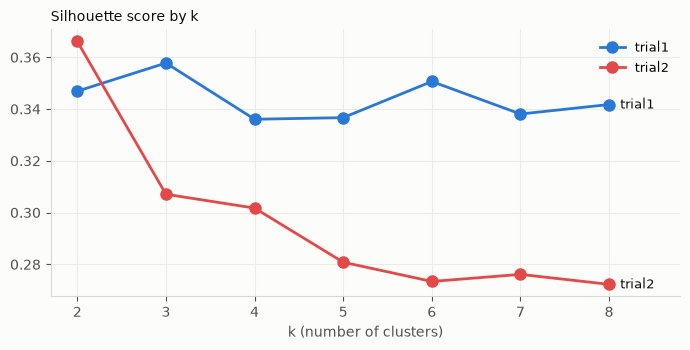

In [9]:
# 試行ごとのシルエット係数。同じ指標なので 1 つの軸で比べる (2 系列のため凡例と直接のラベルを付ける)
TRIAL_COLORS = {"trial1": "#2a78d6", "trial2": "#e34948"}

fig, ax = plt.subplots(figsize=(7, 3.6))
for trial, evaluation in evaluations.items():
    ax.plot(evaluation.index, evaluation["silhouette"], color=TRIAL_COLORS[trial], linewidth=2,
            marker="o", markersize=8, label=trial)
    ax.annotate(trial, (evaluation.index[-1], evaluation["silhouette"].iloc[-1]), xytext=(8, 0),
                textcoords="offset points", va="center", fontsize=9, color=TEXT_PRIMARY)
ax.set_title("Silhouette score by k", fontsize=10, loc="left")
ax.set_xlabel("k (number of clusters)")
ax.set_xticks(list(K_RANGE))
ax.set_xlim(1.7, 8.8)
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

### 評価の考察

- **試行 1**: どの k でも、金額と最近性の両方が分割に効いている (k ≥ 3 で、R² はどちらも 0.5 以上)。シルエット係数は 0.34〜0.36 で、k によってほとんど変わらない。
- **試行 2**: k = 2 では、レビューだけで分かれる (R² はレビュー 0.77、金額と日数は 0.00)。k を増やすと、金額と日数も効くようになる。シルエット係数は k = 2 が最も高く、k が増えると下がる。
- k = 3〜6 では、初期値を変えても結果がほぼ一致する (`ari_min` は試行 2 の k = 5 の 0.89 を除き、0.97 以上)。k = 7・8 は、試行によって一致度が下がる。

## 4. クラスタごとの顧客像

k = 3〜5 について、クラスタごとに加工前の値を見る。入力に使っていない特徴量 (コメント・カード・複数商品) も、解釈のためにあわせて見る。

- 金額と日数は偏りが大きいため、中央値を見る
- `review_5_share`: レビューが 5 の顧客の割合

In [10]:
def profile(trial: str, k: int) -> pd.DataFrame:
    """クラスタごとの顧客数・構成比と、解釈に使う値を返す。"""
    grouped = train_raw.assign(cluster=labels[(trial, k)]).groupby("cluster")
    return pd.DataFrame({
        "n": grouped.size(),
        "share": grouped.size() / len(train_raw),
        "amount_median": grouped["total_items_amount"].median(),
        "days_median": grouped["days_since_last_purchase"].median(),
        "review_mean": grouped["avg_review_score"].mean(),
        "review_5_share": grouped["avg_review_score"].apply(lambda s: (s == 5).mean()),
        "comment_share": grouped["has_review_comment"].mean(),
        "card_share": grouped["credit_card_order_ratio"].mean(),
        "multi_item_share": grouped["item_count"].apply(lambda s: (s >= 2).mean()),
    }).round(3)


for trial in TRIALS:
    for k in (3, 4, 5):
        print(f"{trial} k={k}")
        display(profile(trial, k))

trial1 k=3


,n,share,amount_median,days_median,review_mean,review_5_share,comment_share,card_share,multi_item_share
cluster,,,,,,,,,
0,29667,0.354,159.00,151.0,4.247,0.617,0.431,0.808,0.147
1,28368,0.338,42.90,149.0,4.327,0.628,0.394,0.742,0.052
2,25866,0.308,79.99,419.0,4.293,0.617,0.407,0.759,0.094


trial1 k=4


,n,share,amount_median,days_median,review_mean,review_5_share,comment_share,card_share,multi_item_share
cluster,,,,,,,,,
0,24859,0.296,149.00,126.0,4.256,0.620,0.431,0.804,0.140
1,23227,0.277,44.90,126.0,4.338,0.634,0.400,0.746,0.053
2,18173,0.217,45.99,377.0,4.303,0.615,0.385,0.730,0.057
3,17642,0.210,149.99,379.0,4.254,0.611,0.423,0.799,0.142


trial1 k=5


...

,n,share,amount_median,days_median,review_mean,review_5_share,comment_share,card_share,multi_item_share
cluster,,,,,,,,,
0,40218,0.479,84.99,124.0,4.759,0.760,0.369,0.777,0.075
1,30565,0.364,84.90,386.0,4.658,0.704,0.364,0.764,0.083
2,13118,0.156,90.00,209.0,1.984,0.000,0.649,0.768,0.206


trial2 k=4


,n,share,amount_median,days_median,review_mean,review_5_share,comment_share,card_share,multi_item_share
cluster,,,,,,,,,
0,25052,0.299,159.00,148.0,4.721,0.743,0.378,0.809,0.114
1,24602,0.293,39.99,144.0,4.666,0.715,0.358,0.742,0.042
2,22865,0.273,79.90,422.0,4.632,0.695,0.370,0.759,0.082
3,11382,0.136,99.00,222.0,1.829,0.000,0.680,0.771,0.220


trial2 k=5


,n,share,amount_median,days_median,review_mean,review_5_share,comment_share,card_share,multi_item_share
cluster,,,,,,,,,
0,22648,0.270,139.9,121.0,4.711,0.740,0.381,0.804,0.107
1,19535,0.233,39.9,126.0,4.652,0.710,0.362,0.742,0.040
2,17124,0.204,49.5,385.0,4.617,0.686,0.354,0.735,0.051
3,13818,0.165,169.0,385.0,4.641,0.702,0.378,0.801,0.126
4,10776,0.128,98.0,222.0,1.765,0.000,0.693,0.771,0.226


### 顧客像の考察

**試行 1** (金額と最近性)

- k = 4 では、「金額が小さい / 大きい」(中央値 約 45 / 約 150) と「最近購入 / 以前に購入」(中央値 約 126 日 / 約 378 日) の組み合わせで、4 つにほぼ均等に分かれた。
- k = 5 では、さらに金額の大きいクラスタ (中央値 375、9.5%) が分かれた。
- 入力に使っていない特徴量は、金額の大きいクラスタで、複数商品の割合 (約 14% と 約 5%) とカードの割合 (約 80% と 約 74%) がやや高い。レビューの平均は、どのクラスタも 4.2〜4.4 で差が小さい。

**試行 2** (＋ レビュー)

- k = 3〜5 のいずれでも、レビューの低いクラスタ (平均 1.8〜2.0、5 の割合 0%) が 1 つでき、残りが金額と最近性で分かれた。
- 残りのクラスタでは、試行 1 と同じような金額と最近性の違いが残っている (k = 4 では、金額の大きい最近の顧客 / 金額の小さい最近の顧客 / 以前に購入した顧客)。
- レビューの低いクラスタは、コメントがある割合 (約 68%) と、複数商品の割合 (約 22%) が、ほかのクラスタ (約 37%、約 4〜11%) より高い。理由は、このデータでは確認していない。

### クラスタの中心の位置 (k = 4)

金額と最近性の 2 次元の分布に、各クラスタの金額と日数の中央値を重ねる。ラベルの番号は、上の表のクラスタの番号。

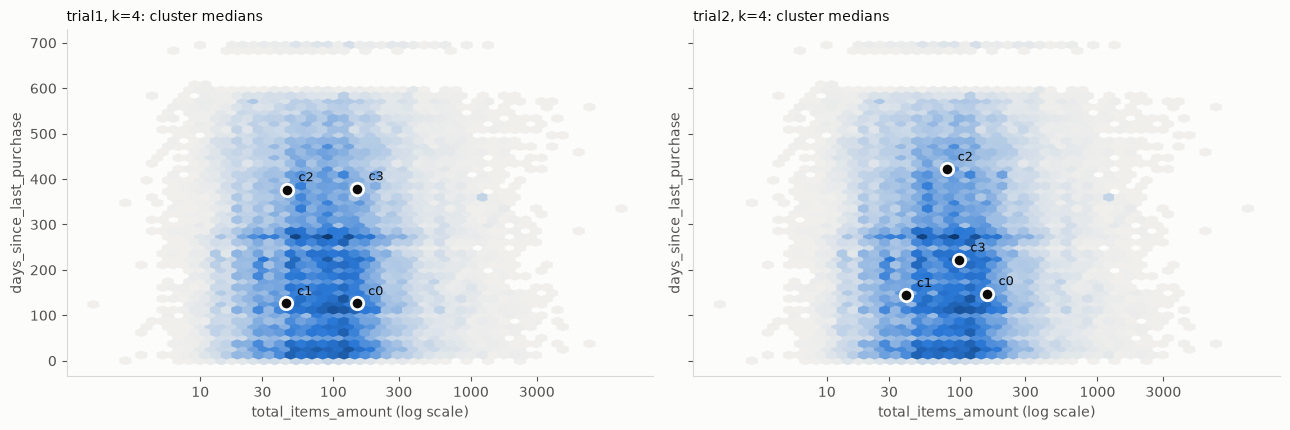

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for ax, trial in zip(axes, TRIALS):
    draw_density(ax)
    summary = profile(trial, 4)
    for cluster, row in summary.iterrows():
        x = np.log1p(row["amount_median"])
        y = row["days_median"]
        ax.scatter(x, y, s=80, color=TEXT_PRIMARY, edgecolor=SURFACE, linewidth=2, zorder=3)
        ax.annotate(f"c{cluster}", (x, y), xytext=(8, 6),
                    textcoords="offset points", fontsize=9, color=TEXT_PRIMARY)
    ax.set_title(f"{trial}, k=4: cluster medians", fontsize=10, loc="left")
fig.tight_layout()
plt.show()

### 試行 2 のレビューの低いクラスタ

試行 2 で、レビューの値がクラスタごとにどう分かれたかを見る (k = 4)。

In [12]:
pd.crosstab(labels[("trial2", 4)], train_raw["avg_review_score"], margins=True)

avg_review_score,1.0,2.0,3.0,4.0,5.0,All
row_0,,,,,,
0,0,0,554,5885,18613,25052
1,0,1,1198,5816,17587,24602
2,0,6,1426,5540,15893,22865
3,5556,2217,3609,0,0,11382
All,5556,2224,6787,17241,52093,83901


### 試行 1 と試行 2 の対応 (k = 4)

試行 2 のクラスタが、試行 1 のどのクラスタから来ているかを見る。

In [13]:
pd.crosstab(
    pd.Series(labels[("trial1", 4)], name="trial1"),
    pd.Series(labels[("trial2", 4)], name="trial2"),
    margins=True,
)

trial2,0,1,2,3,All
trial1,,,,,
0,20554,294,9,4002,24859
1,0,20526,0,2701,23227
2,4,3782,12277,2110,18173
3,4494,0,10579,2569,17642
All,25052,24602,22865,11382,83901


### 試行 2 のレビューの扱いの考察

- 試行 2 の k = 4 で、レビューの低いクラスタ (c3) には、レビューが 1・2 の顧客の全員と、3 の顧客の約半分 (6,787 人中 3,609 人) が入った。4・5 の顧客は入っていない。
- つまり、レビューは「低いか (1〜3)、高いか (4〜5)」の境目でクラスタを分けている。これは条件で書ける分け方に近く、[03_clustering.ipynb](03_clustering.ipynb) で 0 / 1 に近い特徴量に起きたことと同じ傾向。
- c3 は、試行 1 のすべてのクラスタから来ている。レビューの低い顧客は、金額や購入時期によらず現れている。

## まとめ

### 試行 1: 金額と最近性

- 金額と最近性の組み合わせで、解釈しやすい顧客群が得られた (例: 金額が大きく最近購入した顧客)。
- ただし、2 次元の分布には、はっきり分かれた塊がない。K-means は、**自然にまとまった顧客群を見つけたというより、連続した分布を区切った**と考えられる。シルエット係数が k によってほとんど変わらないことも、これと合っている。
- クラスタリングの対象は全員が 1 回購入のため、最近性は「いつ購入したか」を表す。顧客の行動の違いというより、購入した時期の違いとして解釈する必要がある。

### 試行 2: ＋ レビュー

- レビューを加えると、レビューの低い顧客 (1〜3) が 1 つのクラスタとして切り出され、残りでは金額と最近性の違いが保たれた。
- レビューの低いクラスタの境目は、ほぼレビューの値の閾値で決まっている。満足度の違いを捉えたとは言えるが、K-means でなければ見つけられない違いではない。

### 全体

- フラグで分けたことで、0 / 1 に近い値に支配されない分割が得られた。
- 一方で、残りの顧客では、金額・最近性・レビューのいずれでも、はっきり分かれた塊は見られなかった。得られたクラスタは、それぞれの値の高い・低いの組み合わせとして説明できる。